# Which angle launched the ball?

**A small simulation-based inference project using a conditional normalizing flow.**

We observe one number: the distance at which a ball lands. We want a probability
distribution over its launch angle. Different angles can give the same range,
so predicting just one angle would hide part of the answer.

This is a simplified adaptation of the ball example in *Simulation-Based
Inference: A Practical Guide*, Section 2 and Figure 2. We keep its angle-only
inference problem, a truncated-Normal prior, random tailwind, and measurement
noise. We omit air resistance, use explicit SI parameters, and model measurement
noise as Gaussian. This lets us derive the physics directly. It is not an exact
reproduction of the paper's numerical simulator.

Read from top to bottom. Use **Restart Kernel and Run All** to reproduce the
saved results. `projectile.py` contains the physics and the reference posterior;
`flow.py` contains the neural density model. The training loop is visible here.
The accompanying report derives the mathematics in more detail.

In [1]:
from pathlib import Path
from copy import deepcopy
import importlib.metadata
import json
import os
import time

PROJECT = Path.cwd()
RESULTS = PROJECT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT / ".cache" / "matplotlib"))

import numpy as np
import scipy
from scipy.signal import find_peaks
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

from projectile import (
    SPEED, GRAVITY, WIND_RATE, MEASUREMENT_SD, PRIOR_MEAN, PRIOR_SD,
    sample_prior, prior_density, trajectory, simulate, reference_posterior,
)
from flow import ConditionalAngleFlow

torch.set_num_threads(2)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})
VERSIONS = {"torch": torch.__version__, "numpy": np.__version__,
            "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
            "nflows": importlib.metadata.version("nflows")}
print("CPU execution, two PyTorch threads. Package versions:", VERSIONS)

NUM_SIMULATIONS = 20_000
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 15
LEARNING_RATE = 1e-3
OBSERVED_DISTANCES = [13.0, 15.0, 16.0]
NUM_POSTERIOR_SAMPLES = 20_000

def show_and_save(figure, name):
    figure.savefig(FIGURES / f"{name}.png", dpi=170, bbox_inches="tight")
    figure.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{name}.png")))
    plt.close(figure)

Matplotlib is building the font cache; this may take a moment.


CPU execution, two PyTorch threads. Package versions: {'torch': '2.7.1', 'numpy': '2.1.3', 'scipy': '1.15.3', 'matplotlib': '3.10.3', 'nflows': '0.14'}


## 1. The forward problem: an angle gives a trajectory

Let $\theta$ be the angle in **radians** in these physics equations. The ball
starts at ground level, with speed $v_0=13$ m/s. Gravity is $g=9.81$ m/s².
During one flight, the tailwind gives a constant horizontal acceleration $W$:

$$X(t)=v_0\cos\theta\,t+\tfrac12Wt^2,\qquad
Y(t)=v_0\sin\theta\,t-\tfrac12gt^2.$$

Set $Y(T)=0$ and discard the starting solution $T=0$:

$$T=\frac{2v_0\sin\theta}{g}.$$

Substitute into $X(t)$ to get the noise-free landing distance:

$$D(\theta,W)=\underbrace{\frac{v_0^2}{g}\sin(2\theta)}_{A(\theta)}
+\underbrace{\tfrac12T^2}_{B(\theta)}W.$$

The Python interface uses degrees, named `angle_deg`, and converts with
`np.deg2rad` for the trigonometry. All angle densities in this project are
**per degree**, so the density plots and numerical integrals use the same units.

With no wind, $\sin(2\theta)=\sin(2(\pi/2-\theta))$. A low angle and its
complement can therefore give exactly the same range. Random wind changes the
two trajectories differently because their flight times differ.

No-wind angles for 13 m: 24.50 and 65.50 degrees


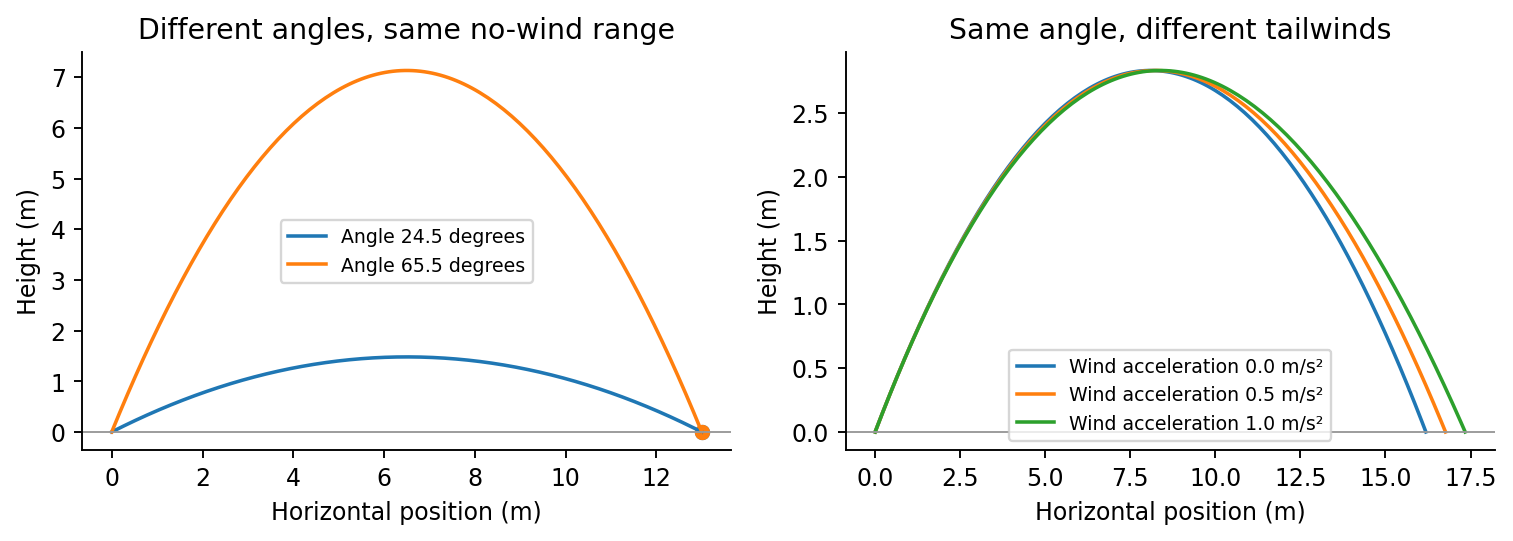

In [2]:
# A no-wind illustration of two different angles producing a 13-metre range.
distance = 13.0
low_angle = np.rad2deg(0.5 * np.arcsin(GRAVITY * distance / SPEED**2))
high_angle = 90.0 - low_angle
print(f"No-wind angles for 13 m: {low_angle:.2f} and {high_angle:.2f} degrees")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for angle in [low_angle, high_angle]:
    t, horizontal, height = trajectory(angle)
    axes[0].plot(horizontal, height, label=f"Angle {angle:.1f} degrees")
    axes[0].scatter(horizontal[-1], 0, s=30)
axes[0].axhline(0, color="0.6", lw=0.8)
axes[0].set(title="Different angles, same no-wind range", xlabel="Horizontal position (m)",
            ylabel="Height (m)")
axes[0].legend(fontsize=8)

for wind in [0.0, 0.5, 1.0]:
    t, horizontal, height = trajectory(35.0, wind_acceleration=wind)
    axes[1].plot(horizontal, height, label=f"Wind acceleration {wind:.1f} m/s²")
axes[1].axhline(0, color="0.6", lw=0.8)
axes[1].set(title="Same angle, different tailwinds", xlabel="Horizontal position (m)",
            ylabel="Height (m)")
axes[1].legend(fontsize=8)
fig.tight_layout()
show_and_save(fig, "trajectories")

## 2. Add a prior and two sources of randomness

Write $\alpha$ for the angle in degrees, so $\theta=\pi\alpha/180$.

$$\alpha\sim N(35,15^2)\text{ restricted to }(0,90),\qquad
W\sim\operatorname{Exponential}(2),\qquad
\varepsilon\sim N(0,0.25^2).$$

For each throw, these draws are independent. The recorded distance is
$x=D(\theta,W)+\varepsilon$. Wind is an **unobserved nuisance variable**: it
affects the data, but we do not ask the network to estimate it. Drawing a new
wind for every simulated throw automatically includes its uncertainty.

The numbers 35 and 15 describe the Normal before truncation; the truncated
prior's mean and standard deviation are slightly different. The code uses
SciPy's normalized truncated-Normal distribution.

We will treat 13, 15, and 16 metres as hypothetical observations. They do not have
one known "true angle". The goal is to infer all plausible angles for each one.

Parameters: (20000, 1) = one angle per row
Simulations: (20000, 1) = one measured range per row
First three (angle in degrees, distance in metres) pairs:
tensor([[21.6633, 11.7906],
        [40.5122, 17.7489],
        [33.9629, 15.9986]])


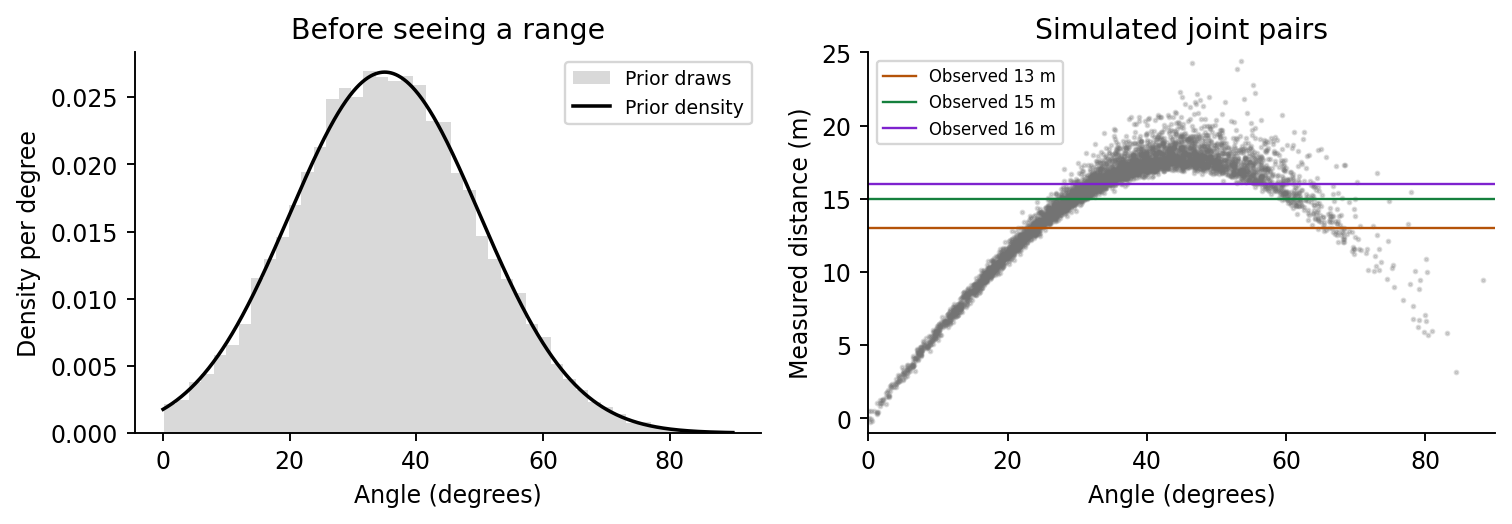

In [3]:
rng = np.random.default_rng(2026)
angles = torch.tensor(sample_prior(NUM_SIMULATIONS, rng), dtype=torch.float32)
distances = torch.tensor(simulate(angles.numpy(), rng), dtype=torch.float32)
print("Parameters:", tuple(angles.shape), "= one angle per row")
print("Simulations:", tuple(distances.shape), "= one measured range per row")
print("First three (angle in degrees, distance in metres) pairs:")
print(torch.cat([angles[:3], distances[:3]], dim=1))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
grid = np.linspace(0, 90, 1000)
axes[0].hist(angles[:, 0].numpy(), bins=45, density=True, color="0.85", label="Prior draws")
axes[0].plot(grid, prior_density(grid), color="black", label="Prior density")
axes[0].set(xlabel="Angle (degrees)", ylabel="Density per degree", title="Before seeing a range")
axes[0].legend(fontsize=8)
axes[1].scatter(angles[::4, 0], distances[::4, 0], s=2, color="0.45", alpha=0.25, rasterized=True)
for distance, color in zip(OBSERVED_DISTANCES, ["#b45309", "#15803d", "#7e22ce"]):
    axes[1].axhline(distance, color=color, lw=1, label=f"Observed {distance:.0f} m")
axes[1].set(xlim=(0, 90), ylim=(-1, 25), xlabel="Angle (degrees)",
            ylabel="Measured distance (m)", title="Simulated joint pairs")
axes[1].legend(fontsize=7)
fig.tight_layout()
show_and_save(fig, "prior_and_joint")

## 3. Learn the inverse problem with NPE

Simulation gives an angle first and data second. Inference goes in the reverse
direction: given the data, learn a density over angles.

For each simulated pair $(\alpha_i,x_i)$, the network evaluates
$q_\phi(\alpha_i\mid x_i)$. We minimize the **negative log density**:

$$\widehat{\mathcal L}(\phi)=-\frac1N\sum_i\log q_\phi(\alpha_i\mid x_i).$$

For a batch of $B$ pairs, angle and distance tensors both have shape `(B, 1)`.
The log-density tensor has shape `(B,)`: one score per pair. PyTorch uses a
**tensor**, an array with automatic derivatives, to train the network.

In the population, adding and subtracting $\log p(\alpha\mid x)$ gives

$$\mathcal L(\phi)=H(\mathrm{Angle}\mid X)+
\mathbb E_{p(x)}D_{\rm KL}\{p(\alpha\mid x)\Vert q_\phi(\alpha\mid x)\}.$$

The first term does not change when the weights change. This explains why the
training target is a posterior distribution. It does not guarantee exact
inference from a finite network and simulation budget.

## 4. What the normalizing flow does

Start with an easy random number $z\sim N(0,1)$. Three invertible spline maps,
conditioned on the distance $x$, turn it into $u$. Then set

$$\alpha=90\operatorname{sigmoid}(u),\qquad
u=\log\frac{\alpha}{90-\alpha}.$$

This gives angles strictly between zero and 90 degrees without clipping them.
A spline is a smooth curve made of simple pieces. A small network predicts the
widths, heights, and slopes of those pieces from the distance. Positive widths,
heights, and slopes keep the curve increasing and invertible. Its slope can
vary, allowing the transformed density to have two peaks.

The spline arithmetic comes from `nflows`. Open `flow.py` to see the small
conditioning networks and the rest of the density calculation. We use three
layers, 16 bins per layer, and two hidden layers of 32 tanh units per network.
Outside the spline interval $[-5,5]$, each spline is the identity.

For density evaluation, run the transformations backwards to get $z$:

$$\log q_\phi(\alpha\mid x)=\log p_Z(z)
+\log\left|\frac{\partial z}{\partial\alpha}\right|.$$

The angle-bound transformation contributes
$-\log90-\log(\alpha/90)-\log(1-\alpha/90)$ to this inverse log-Jacobian.
The report gives the spline bin formula and derivative as well.

In [4]:
torch.manual_seed(42)
demo = ConditionalAngleFlow()
print("One conditioning network (input is one standardized distance):")
print(demo.layers[0].network)
z = torch.tensor([[-1.0], [0.0], [1.0]])
demo_angles, forward_det = demo.to_angles(z, 13.0)
recovered_z, inverse_det = demo.to_base(demo_angles, 13.0)
print("Base values:", z[:, 0].numpy())
print("Angles before training:", demo_angles[:, 0].detach().numpy())
print("Recovered base values:", recovered_z[:, 0].detach().numpy())
print("Forward + inverse log-Jacobian:", (forward_det + inverse_det).detach().numpy())

One conditioning network (input is one standardized distance):
Sequential(
  (0): Linear(in_features=1, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): Tanh()
  (4): Linear(in_features=32, out_features=47, bias=True)
)
Base values: [-1.  0.  1.]
Angles before training: [24.20473 45.      65.79527]
Recovered base values: [-0.99999994  0.          1.0000001 ]
Forward + inverse log-Jacobian: [-2.3841858e-07  2.3841858e-07  2.3841858e-07]


## 5. The complete training loop

An **epoch** is one pass through the training pairs. A **batch** is a small group
processed at once. `loss.backward()` calculates derivatives of the loss;
`optimizer.step()` updates the network weights.

We reserve 10% of the pairs for validation and compute distance standardization
from the training set only. Validation data do not update the weights. We keep
the best validation weights and stop after 15 epochs without an improvement of
at least $10^{-4}$, with a limit of 100 epochs. Gradient clipping at 5 limits
very large updates. There are no likelihood evaluations in this training code.

Epoch   1: train NLL=3.191, validation NLL=2.942


Epoch  10: train NLL=2.539, validation NLL=2.472


Epoch  20: train NLL=2.461, validation NLL=2.409


Epoch  30: train NLL=2.466, validation NLL=2.506


Epoch  40: train NLL=2.470, validation NLL=2.396


Restored epoch 31; CPU training: 39.3 seconds.


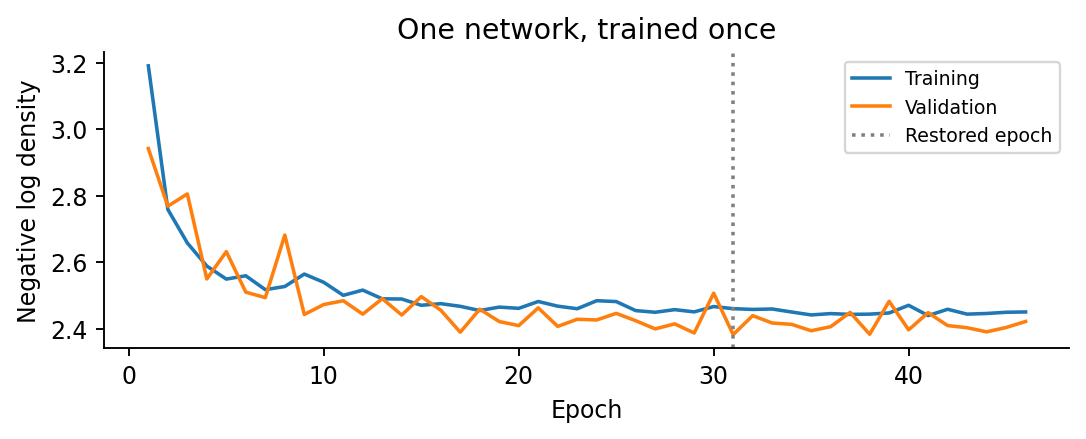

In [5]:
def train_flow(angles, distances):
    torch.manual_seed(42)
    started = time.perf_counter()
    order = torch.randperm(len(angles))
    split = int(0.9 * len(angles))
    train_rows, validation_rows = order[:split], order[split:]
    train_angles, train_distances = angles[train_rows], distances[train_rows]
    validation_angles, validation_distances = angles[validation_rows], distances[validation_rows]

    model = ConditionalAngleFlow(num_layers=3, num_bins=16, hidden_size=32)
    model.fit_standardization(train_distances)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_loss = float("inf")
    epochs_without_improvement = 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        shuffled = torch.randperm(len(train_angles))
        total_loss = 0.0
        for rows in shuffled.split(BATCH_SIZE):
            loss = -model.log_prob(train_angles[rows], train_distances[rows]).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite loss; inspect the training run.")
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0, error_if_nonfinite=True)
            optimizer.step()
            total_loss += loss.item() * len(rows)

        model.eval()
        with torch.no_grad():
            validation_loss = -model.log_prob(validation_angles, validation_distances).mean().item()
        if not np.isfinite(validation_loss):
            raise FloatingPointError("Non-finite validation loss.")
        history.append({"epoch": epoch, "training_nll": total_loss / len(train_angles),
                        "validation_nll": validation_loss})
        if validation_loss < best_loss - 1e-4:
            best_loss = validation_loss
            best_epoch = epoch
            best_weights = deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epoch == 1 or epoch % 10 == 0:
            print(f"Epoch {epoch:3d}: train NLL={history[-1]['training_nll']:.3f}, "
                  f"validation NLL={validation_loss:.3f}", flush=True)
        if epochs_without_improvement >= PATIENCE:
            break

    model.load_state_dict(best_weights)
    model.eval()
    summary = {"epochs_run": epoch, "best_epoch": best_epoch,
               "best_validation_nll": best_loss,
               "training_seconds": time.perf_counter() - started,
               "training_pairs": len(train_rows), "validation_pairs": len(validation_rows)}
    return model, history, summary

model, history, training = train_flow(angles, distances)
print(f"Restored epoch {training['best_epoch']}; CPU training: {training['training_seconds']:.1f} seconds.")
torch.save({"model_state_dict": model.state_dict(),
            "model_kwargs": {"num_layers": 3, "num_bins": 16, "hidden_size": 32}},
           RESULTS / "angle_flow.pt")

fig, ax = plt.subplots(figsize=(6.5, 2.7))
ax.plot([r["epoch"] for r in history], [r["training_nll"] for r in history], label="Training")
ax.plot([r["epoch"] for r in history], [r["validation_nll"] for r in history], label="Validation")
ax.axvline(training["best_epoch"], color="0.5", linestyle=":", label="Restored epoch")
ax.set(xlabel="Epoch", ylabel="Negative log density", title="One network, trained once")
ax.legend(fontsize=8)
fig.tight_layout()
show_and_save(fig, "training")

## 6. A numerical reference for checking the learned answer

Given an angle and a wind acceleration, the measurement model is Gaussian:

$$p(x\mid\alpha,w)=N\!\left(x;A(\alpha)+B(\alpha)w,\sigma_x^2\right).$$

Here $A$ and $B$ use the degree-to-radian conversion. To check the network, we
integrate over the unobserved wind and then use Bayes' rule:

$$p(x\mid\alpha)=\int_0^\infty p(x\mid\alpha,w)\,2e^{-2w}\,dw,
\qquad p(\alpha\mid x)=
\frac{p(x\mid\alpha)p(\alpha)}{\int_0^{90}p(x\mid a)p(a)\,da}.$$

`reference_posterior` in `projectile.py` performs the wind integral using adaptive
quadrature and the angle integral using a midpoint grid. We compare grids with
2,000 and 4,000 angle points. The calculation is feasible for this toy example;
it would often be unavailable in a real SBI problem. It is **not used to train**.

For each observation we also evaluate the learned density without normalizing
it again. Its grid integral should be near one. Total variation (TV) measures
its difference from the reference:

$$\operatorname{TV}(p,q)=\tfrac12\int_0^{90}|p(\alpha\mid x)-q(\alpha\mid x)|\,d\alpha.$$

TV is zero for agreement and at most one. We also report $P(\alpha<45^\circ\mid x)$
as a simple comparison of low- versus high-angle probability. This is a fixed
45-degree partition, not a fitted boundary between modes.


Observed 13 m: TV=0.0686, learned integral=1.000006
  Reference modes (degrees): [24.02 66.27]
  Flow modes (degrees):      [23.88 66.77]
  P(angle < 45): reference=0.8990, flow=0.9107



Observed 15 m: TV=0.0997, learned integral=0.999996
  Reference modes (degrees): [29.49 60.69]
  Flow modes (degrees):      [29.06 61.28]
  P(angle < 45): reference=0.8385, flow=0.8575



Observed 16 m: TV=0.0598, learned integral=0.999997
  Reference modes (degrees): [32.97 57.07]
  Flow modes (degrees):      [32.57 57.5 ]
  P(angle < 45): reference=0.7850, flow=0.7944


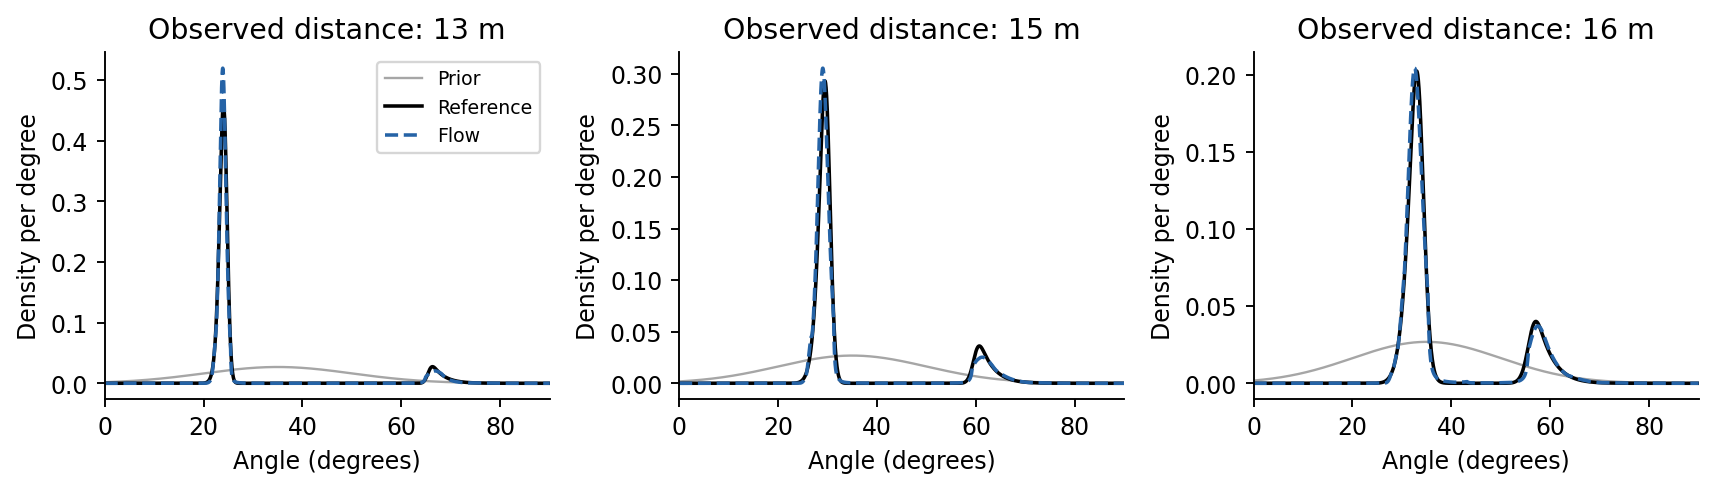

In [6]:
@torch.no_grad()
def learned_density(model, angle_grid, distance):
    values = torch.tensor(angle_grid[:, None], dtype=torch.float32)
    return model.log_prob(values, distance).exp().numpy().astype(np.float64)

references, learned_grids, posterior_samples, diagnostics = {}, {}, {}, {}
for index, distance in enumerate(OBSERVED_DISTANCES):
    coarse = reference_posterior(distance, 2000)
    fine = reference_posterior(distance, 4000)
    coarse_q = learned_density(model, coarse["angle_deg"], distance)
    q = learned_density(model, fine["angle_deg"], distance)
    mass = float(q.sum() * fine["step"])
    coarse_mass = float(coarse_q.sum() * coarse["step"])
    tv = float(0.5 * np.abs(q - fine["density"]).sum() * fine["step"])
    coarse_tv = float(0.5 * np.abs(coarse_q - coarse["density"]).sum() * coarse["step"])
    torch.manual_seed(100 + index)
    draws = model.sample(NUM_POSTERIOR_SAMPLES, distance).numpy()[:, 0]
    assert np.isfinite(q).all() and ((draws > 0) & (draws < 90)).all()
    mean_change = abs(fine["mean_deg"] - coarse["mean_deg"])
    branch_change = abs(fine["low_angle_probability"] - coarse["low_angle_probability"])
    assert mean_change < 0.001 and branch_change < 1e-4, "Refine the reference grid."
    assert abs(mass - coarse_mass) < 0.001 and abs(tv - coarse_tv) < 0.001, "Refine the flow grid."
    assert abs(mass - 1.0) < 0.001, "Check density normalization and quadrature."
    ref_peaks, _ = find_peaks(fine["density"], prominence=0.02 * fine["density"].max())
    flow_peaks, _ = find_peaks(q, prominence=0.02 * q.max())
    references[distance], learned_grids[distance], posterior_samples[distance] = fine, q, draws
    diagnostics[str(int(distance))] = {
        "reference_modes_deg": fine["angle_deg"][ref_peaks].tolist(),
        "flow_modes_deg": fine["angle_deg"][flow_peaks].tolist(),
        "reference_mean_deg": fine["mean_deg"], "sample_mean_deg": float(draws.mean()),
        "reference_low_angle_probability": fine["low_angle_probability"],
        "flow_low_angle_probability": float(q[fine["angle_deg"] < 45].sum() * fine["step"]),
        "learned_integral": mass, "total_variation": tv,
        "reference_mean_grid_change_deg": mean_change,
        "reference_branch_grid_change": branch_change,
        "learned_integral_grid_change": abs(mass - coarse_mass),
        "tv_grid_change": abs(tv - coarse_tv), "wind_quadrature_error": fine["quadrature_error"],
    }
    np.savez_compressed(RESULTS / f"posterior_{int(distance)}m.npz",
                        angle_deg=fine["angle_deg"], reference_density=fine["density"],
                        learned_density=q, samples_deg=draws)
    print(f"\nObserved {distance:.0f} m: TV={tv:.4f}, learned integral={mass:.6f}")
    print("  Reference modes (degrees):", np.round(fine["angle_deg"][ref_peaks], 2))
    print("  Flow modes (degrees):     ", np.round(fine["angle_deg"][flow_peaks], 2))
    print(f"  P(angle < 45): reference={fine['low_angle_probability']:.4f}, "
          f"flow={diagnostics[str(int(distance))]['flow_low_angle_probability']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.0))
for distance, ax in zip(OBSERVED_DISTANCES, axes):
    grid = references[distance]
    ax.plot(grid["angle_deg"], prior_density(grid["angle_deg"]), color="0.65", lw=1, label="Prior")
    ax.plot(grid["angle_deg"], grid["density"], color="black", label="Reference")
    ax.plot(grid["angle_deg"], learned_grids[distance], color="#2563a6", ls="--", label="Flow")
    ax.set(title=f"Observed distance: {distance:.0f} m", xlabel="Angle (degrees)",
           ylabel="Density per degree", xlim=(0, 90))
axes[0].legend(fontsize=8)
fig.tight_layout()
show_and_save(fig, "posterior_comparison")

## 7. See the learned transformation

For one fixed distance, an invertible one-dimensional flow is an increasing
curve. It preserves the order of samples but changes their spacing. Where
Gaussian samples are squeezed into a narrow range of angles, angle density
increases. Varying the slope lets an increasing map produce a density with
multiple peaks. Invertibility does **not** imply a unimodal density.

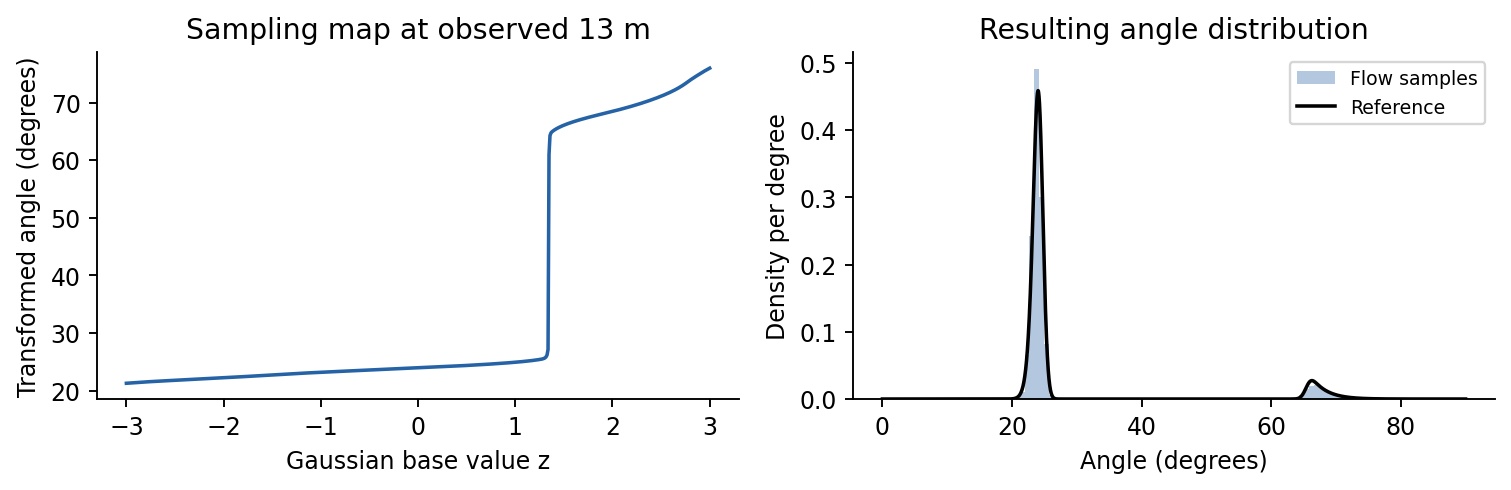

In [7]:
with torch.no_grad():
    z = torch.linspace(-3, 3, 600)[:, None]
    mapped, _ = model.to_angles(z, 13.0)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0))
axes[0].plot(z[:, 0], mapped[:, 0], color="#2563a6")
axes[0].set(xlabel="Gaussian base value z", ylabel="Transformed angle (degrees)",
            title="Sampling map at observed 13 m")
axes[1].hist(posterior_samples[13.0], bins=np.linspace(0, 90, 120), density=True,
             color="#2563a6", alpha=0.35, label="Flow samples")
axes[1].plot(references[13.0]["angle_deg"], references[13.0]["density"], color="black", label="Reference")
axes[1].set(xlabel="Angle (degrees)", ylabel="Density per degree", title="Resulting angle distribution")
axes[1].legend(fontsize=8)
fig.tight_layout()
show_and_save(fig, "flow_map")

## 8. Posterior predictive check

For each inferred angle, throw the ball again with a **new** random wind and new
measurement noise. This gives $p(x_{\rm new}\mid x_{\rm obs})$. Its width reflects
remaining angle uncertainty and randomness in future throws.

The dashed line marks the original observation; a future throw need not land
at exactly that distance. This is a check of the assumed simulator, not a
validation experiment with independent real data. A plausible predictive plot
alone does not prove that the angle posterior is accurate.

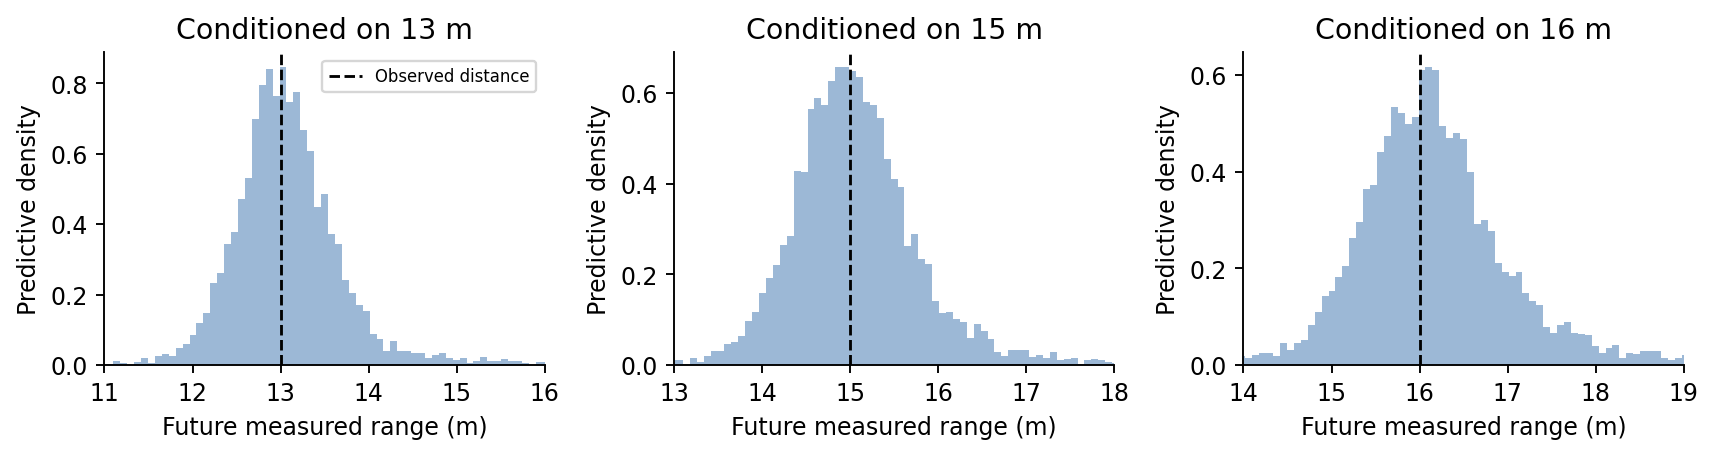

Saved weights, posterior arrays, figures, metrics, and report table under results/.


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10.2, 2.8))
for index, (distance, ax) in enumerate(zip(OBSERVED_DISTANCES, axes)):
    draws = posterior_samples[distance][:5000, None]
    predictions = simulate(draws, np.random.default_rng(200 + index))[:, 0]
    ax.hist(predictions, bins=np.linspace(distance - 3, distance + 4, 90), density=True,
            color="#2563a6", alpha=0.45)
    ax.axvline(distance, color="black", ls="--", lw=1.2, label="Observed distance")
    ax.set(xlabel="Future measured range (m)", ylabel="Predictive density",
           title=f"Conditioned on {distance:.0f} m", xlim=(distance - 2, distance + 3))
axes[0].legend(fontsize=7)
fig.tight_layout()
show_and_save(fig, "posterior_predictive")

settings = {"num_simulations": NUM_SIMULATIONS, "batch_size": BATCH_SIZE,
            "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "learning_rate": LEARNING_RATE,
            "observed_distances_m": OBSERVED_DISTANCES,
            "num_posterior_samples": NUM_POSTERIOR_SAMPLES,
            "speed_m_per_s": SPEED, "gravity_m_per_s2": GRAVITY,
            "wind_rate": WIND_RATE, "measurement_sd_m": MEASUREMENT_SD,
            "prior_mean_deg": PRIOR_MEAN, "prior_sd_deg": PRIOR_SD, "angle_bounds_deg": [0, 90],
            "num_spline_layers": 3, "bins_per_layer": 16, "hidden_size": 32, "spline_bound": 5,
            "grid_sizes": [2000, 4000], "simulation_seed": 2026, "training_seed": 42,
            "posterior_seeds": [100, 101, 102], "predictive_seeds": [200, 201, 202],
            "versions": VERSIONS, "torch_threads": torch.get_num_threads()}
with open(RESULTS / "metrics.json", "w") as file:
    json.dump({"settings": settings, "training": training, "observations": diagnostics}, file,
              indent=2, allow_nan=False)
with open(RESULTS / "training_history.json", "w") as file:
    json.dump(history, file, indent=2, allow_nan=False)

# Keep the report's numerical table synchronized with the saved results.
table_rows = []
for distance in OBSERVED_DISTANCES:
    d = diagnostics[str(int(distance))]
    modes = ", ".join(f"{a:.2f}" for a in d["reference_modes_deg"])
    table_rows.append(f"{distance:.0f} & {modes} & {d['reference_low_angle_probability']:.4f} & "
                      f"{d['flow_low_angle_probability']:.4f} & {d['total_variation']:.4f} & "
                      f"{d['learned_integral']:.6f} " + r"\\")
(RESULTS / "accuracy_rows.tex").write_text("\n".join(table_rows) + "\n")
numbers = {"BestEpoch": str(training["best_epoch"]), "EpochsRun": str(training["epochs_run"]),
           "TrainSeconds": f"{training['training_seconds']:.1f}",
           "BestValidation": f"{training['best_validation_nll']:.3f}",
           "MaxMeanChange": f"{max(d['reference_mean_grid_change_deg'] for d in diagnostics.values()):.2e}",
           "MaxBranchChange": f"{max(d['reference_branch_grid_change'] for d in diagnostics.values()):.2e}",
           "MaxTVChange": f"{max(d['tv_grid_change'] for d in diagnostics.values()):.2e}",
           "MaxMassChange": f"{max(d['learned_integral_grid_change'] for d in diagnostics.values()):.2e}"}
lines = ["\\newcommand{\\" + key + "}{" + value + "}" for key, value in numbers.items()]
(RESULTS / "report_numbers.tex").write_text("\n".join(lines) + "\n")
print("Saved weights, posterior arrays, figures, metrics, and report table under results/.")

## 9. Reuse the trained network

This is **amortized inference**: after training once, change the observed
distance without retraining. The new data must follow the same simulator and
prior. A changed speed, gravity, noise model, wind distribution, or angle prior
requires new simulations and training.

In [9]:
checkpoint = torch.load(RESULTS / "angle_flow.pt", map_location="cpu", weights_only=True)
reloaded = ConditionalAngleFlow(**checkpoint["model_kwargs"])
reloaded.load_state_dict(checkpoint["model_state_dict"])
reloaded.eval()
torch.manual_seed(300)
new_samples = reloaded.sample(1000, distance_m=15.0)
print("1000 inferred angles:", tuple(new_samples.shape))
print("First five angles (degrees):", new_samples[:5, 0].numpy())
torch.testing.assert_close(reloaded.log_prob(new_samples[:5], 15.0),
                           model.log_prob(new_samples[:5], 15.0))

1000 inferred angles: (1000, 1)
First five angles (degrees): [28.991964 28.918999 29.864359 57.79654  28.384434]


## What to take away

- The network learns a **distribution over angles**, not a unique reconstructed
  launch. Two distinct angle ranges can explain one distance.
- We infer one angle parameter. Wind is marginalized by sampling it inside
  the simulator; it is not held fixed and is not added to the network inputs.
- The prior can give the two angle branches different weights. With the
  35-degree prior used here, low angles are usually favored.
- Correct flow mathematics ensures a valid density model; it does not make the
  trained model exactly equal to the Bayesian posterior. Read the measured
  discrepancies as well as the plots.
- A posterior mean can lie in the low-density gap between modes. It is not
  necessarily a representative angle. Likewise, one broad central interval
  can include angles with little posterior support.
- These are three observations evaluated with **one trained model and one
  training seed**, not a repeated-dataset calibration study.

### References

1. Deistler et al. (2025), [Simulation-Based Inference: A Practical Guide](https://arxiv.org/abs/2508.12939), Section 2 and Figure 2.
2. The authors' [ball-throw implementation](https://github.com/sbi-dev/sbi-practical-guide/blob/main/examples/ball_throw.ipynb). Its drag model and numerical constants differ from this simplified SI example.
3. Weniger (2026), [Lecture 1: ABC and Neural SBI](https://cweniger.github.io/teaching-2608-IAIFI/lecture1.html).
4. Durkan et al. (2019), [Neural Spline Flows](https://arxiv.org/abs/1906.04032), and [nflows](https://github.com/bayesiains/nflows).